## Run the gravity calculation using the following equation:

#### Gravity_mat=(Campsites_mat*np.sqrt(Population_mat))/Distance_mat

In [7]:
import pandas as pd
import numpy as np
import math
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

#import CSV into a dataframe of distance from campground population of urban centre and number of campsites
Camp_Dist_Pop_Sites=pd.read_csv('Campground_Dist_Pop_Sites_matrix.csv',index_col=0)

#Split the dataframe into 3 separate dataframes: 1. distance for origin to campground, 2. Number of campsites, 3. population of origin
Distance_df=Camp_Dist_Pop_Sites[['Distance_Km','Distance_Km.1','Distance_Km.2','Distance_Km.3','Distance_Km.4']]
Campsites_df=Camp_Dist_Pop_Sites[['Sites','Sites.1','Sites.2','Sites.3','Sites.4']]
Population_df=Camp_Dist_Pop_Sites[['Population','Population.1','Population.2','Population.3','Population.4']]

#Rename columns to include origin location and remove the columns that aren't needed anymore
Distance_df=Distance_df.rename(columns={'Distance_Km':'Bedford','Distance_Km.1':'Edmunston','Distance_Km.2':'Fredericton','Distance_Km.3':'Moncton','Distance_Km.4':'Oromocto'}).drop(index=['Origin', 'Campground'])
Campsites_df=Campsites_df.rename(columns={'Sites':'Bedford','Sites.1':'Edmunston','Sites.2':'Fredericton','Sites.3':'Moncton','Sites.4':'Oromocto'}).drop(index=['Origin', 'Campground'])
Population_df=Population_df.rename(columns={'Population':'Bedford','Population.1':'Edmunston','Population.2':'Fredericton','Population.3':'Moncton','Population.4':'Oromocto'}).drop(index=['Origin', 'Campground'])

# convert dataframe to a numpy matrix and convert values to float
Distance_mat=Distance_df.to_numpy().astype(float)
Campsites_mat=Campsites_df.to_numpy().astype(float)
Population_mat=Population_df.to_numpy().astype(float)

In [8]:
#Calculating gravity matrix
Gravity_mat=(Campsites_mat*np.sqrt(Population_mat))/Distance_mat

In [32]:
#Convert numpy matrix back to a dataframe and return to a pandas dataframe
def conv_to_df(matrix,row_name):
    import numpy as mp
    import pandas as pd
    Gravity_df = pd.DataFrame(matrix,index=row_name.index, columns = ['Bedford','Edmunston','Fredericton','Moncton','Oromocto'])
    Gravity_df = Gravity_df[Gravity_df != 0]
    Gravity_df = Gravity_df.dropna()
    return Gravity_df
Gravity_df = conv_to_df(Gravity_mat, Campsites_df)

In [33]:
Gravity_df.sort_values().tail()

TypeError: sort_values() missing 1 required positional argument: 'by'

In [36]:
#Write to csv
Gravity_df.to_csv('Gravity_root(Pop).csv')

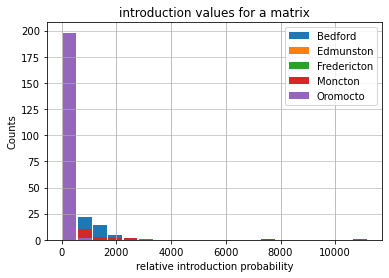

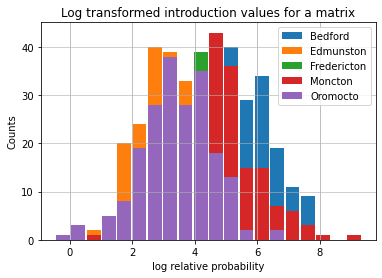

In [35]:
#plot histogram of the distribution by origin location. 
import matplotlib.pyplot as plt

Gravity_df.plot.hist(grid=True, bins=20, rwidth=0.9)
plt.title('introduction values for a matrix')
plt.xlabel('relative introduction probability')
plt.ylabel('Counts')
plt.grid(axis='y', alpha=0.75)

np.log(Gravity_df).plot.hist(grid=True, bins=20, rwidth=0.9)
plt.title('Log transformed introduction values for a matrix')
plt.xlabel('log relative probability')
plt.ylabel('Counts')
plt.grid(axis='y', alpha=0.75)